# Chapitre 3 - Cours 2 : SSTables, arbres LSM et filtres de Bloom

Ce notebook couvre la section *SSTables and LSM-Trees* : ses sous-sections
*Constructing and maintaining SSTables*, *Making an LSM-tree out of SSTables* et
*Performance optimizations* (filtres de Bloom, compaction par paliers de taille et par
niveaux). Nous construisons pas à pas un moteur LSM complet (`S.LSMTree`) et mesurons
ses amplifications d'écriture, de lecture et d'espace.

**Plan.**

1. Les SSTables : des segments triés, un index épars, des blocs compressibles.
2. Construire des SSTables : memtable, écriture sur disque et journal de reprise (WAL).
3. Fusionner des segments : le tri fusion et les tombstones.
4. Les filtres de Bloom : théorie, mesure et effet sur les lectures.
5. Les stratégies de compaction : par paliers de taille ou par niveaux.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Les SSTables (section *SSTables and LSM-Trees*)

**Idée.** Gardons des segments immuables, mais exigeons que chacun soit **trié par clé**
et ne contienne chaque clé **qu'une fois**. On appelle ce format une *Sorted String
Table*, ou **SSTable**. Le tri change tout :

- plus besoin de garder **toutes** les clés en mémoire : on découpe le fichier en
  **blocs** de quelques Kio et on ne retient que la **première clé de chaque bloc**. Cet
  index qui ne contient qu'une partie des clés est dit **épars** (*sparse*). Pour
  chercher une clé absente de l'index, on trouve les deux clés de l'index qui
  l'encadrent, on saute au début du bloc et on le parcourt ;
- chaque bloc peut être **compressé** : moins d'espace disque et moins de bande
  passante d'E/S, au prix d'un peu de CPU ;
- les requêtes **par intervalle** deviennent naturelles (les clés sont dans l'ordre).

In [2]:
items = [(S.kv_key(i), S.kv_value(i, size=100)) for i in range(0, 60_000, 3)]
sst = S.SSTable(items, block_bytes=4096)
st = {}
found, val = sst.get(S.kv_key(30_000), st)
print(f"{len(sst)} clés ; {len(sst.blocks)} blocs de 4 Kio ; index épars de {len(sst.sparse_index)} clés")
print("recherche de user00030000 :", found, "| blocs lus :", st["blocks_read"])
print("deux entrées de l'index qui l'encadrent :",
      sst.sparse_index[np.searchsorted(sst.sparse_index, S.kv_key(30_000), side="right") - 1],
      "<= clé <", sst.sparse_index[np.searchsorted(sst.sparse_index, S.kv_key(30_000), side="right")])

20000 clés ; 607 blocs de 4 Kio ; index épars de 607 clés
recherche de user00030000 : True | blocs lus : 1
deux entrées de l'index qui l'encadrent : user00029997 <= clé < user00030096


Le schéma ci-dessous montre la structure d'une SSTable telle que nous l'avons
implémentée : des blocs de données triés, un index épars (première clé de chaque bloc),
un filtre de Bloom (section 4).

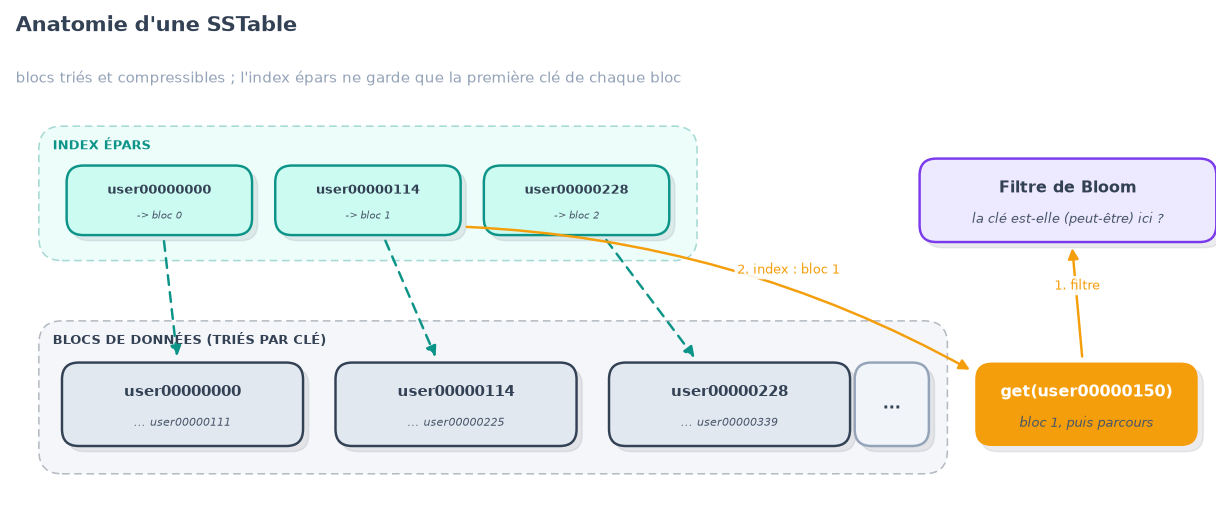

In [3]:
d = Diagram(13, 4.3, title="Anatomie d'une SSTable",
            subtitle="blocs triés et compressibles ; l'index épars ne garde que la première clé de chaque bloc")
d.group(0.3, 0.25, 10.1, 1.9, "blocs de données (triés par clé)", color=SLATE)
blocs = [("user00000000", "... user00000111"), ("user00000114", "... user00000225"),
         ("user00000228", "... user00000339")]
for j, (a, b) in enumerate(blocs):
    d.box(f"b{j}", 1.85 + j * 2.95, 1.0, a, sub=b, color=SLATE, w=2.6, h=0.9, fontsize=9.5)
d.box("etc", 9.5, 1.0, "...", color=GRAY, w=0.8, h=0.9)
d.group(0.3, 2.55, 7.4, 4.0, "index épars", color=TEAL)
for j, (a, _) in enumerate(blocs):
    d.box(f"i{j}", 1.6 + j * 2.25, 3.2, a, sub=f"-> bloc {j}", color=TEAL, w=2.0, h=0.75, fontsize=8.5)
    d.arrow(f"i{j}", f"b{j}", color=TEAL, style="dashed")
d.box("bloom", 11.4, 3.2, "Filtre de Bloom", sub="la clé est-elle (peut-être) ici ?", color=VIOLET, w=3.2, h=0.9)
d.box("q", 11.6, 1.0, "get(user00000150)", sub="bloc 1, puis parcours", color=AMBER, w=2.4, h=0.9, kind="tag")
d.arrow("q", "bloom", "1. filtre", color=AMBER)
d.arrow("i1", "q", "2. index : bloc 1", color=AMBER, rad=-0.12, label_pos=0.62)
d.show()

**Le compromis de la taille de bloc.** Des blocs plus gros réduisent l'index épars (moins
de mémoire) mais obligent à lire et parcourir plus d'octets par recherche. Des blocs
compressés réduisent l'espace disque : nos valeurs synthétiques sont très
répétitives, donc le taux de compression est flatteur, mais la tendance est générale.

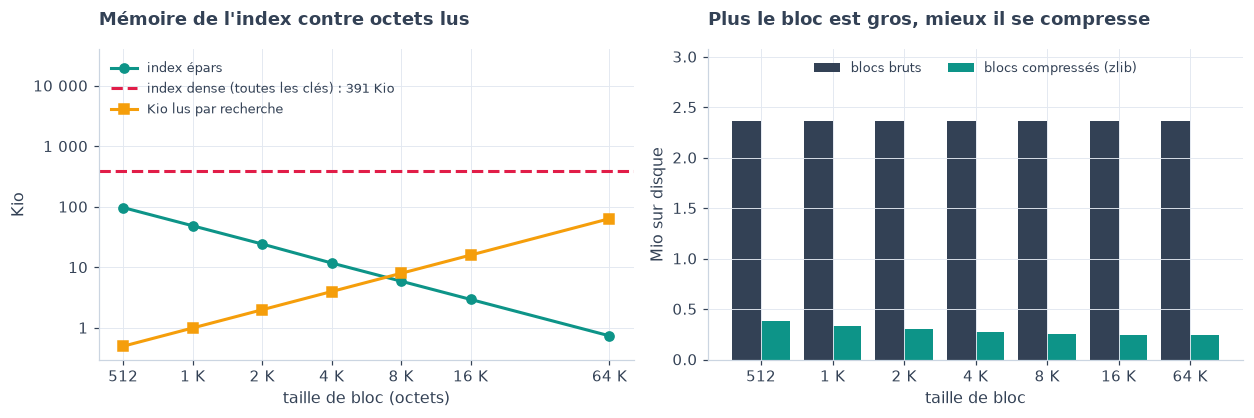

,bloc_octets,entrees_index,index_Kio,octets_lus_par_get,disque_Mio,compresse_Mio
0,512,5000,97.656,512,2.365,0.387
1,1024,2500,48.828,1024,2.365,0.330
2,2048,1250,24.414,2048,2.365,0.306
3,4096,607,11.855,4096,2.365,0.276
4,8192,304,5.938,8192,2.365,0.255
5,16384,152,2.969,16384,2.365,0.246
6,65536,38,0.742,65536,2.365,0.245


In [4]:
rows = []
for bb in [512, 1024, 2048, 4096, 8192, 16384, 65536]:
    t = S.SSTable(items, block_bytes=bb, bloom_bits_per_key=0)
    tc = S.SSTable(items, block_bytes=bb, bloom_bits_per_key=0, compress=True)
    idx_bytes = sum(len(k) + 8 for k in t.sparse_index)
    rows.append(dict(bloc_octets=bb, entrees_index=len(t.sparse_index), index_Kio=idx_bytes / 1024,
                     octets_lus_par_get=bb, disque_Mio=t.size_bytes / 2**20, compresse_Mio=tc.size_bytes / 2**20))
blk = pd.DataFrame(rows)
dense = len(items) * (12 + 8) / 1024
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax = axes[0]
ax.plot(blk.bloc_octets, blk.index_Kio, "o-", color=TEAL, label="index épars")
ax.axhline(dense, color=ROSE, ls="--", label=f"index dense (toutes les clés) : {dense:.0f} Kio")
ax.plot(blk.bloc_octets, blk.octets_lus_par_get / 1024, "s-", color=AMBER, label="Kio lus par recherche")
ax.set_xscale("log", base=2); ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xticks(blk.bloc_octets, [f"{b // 1024} K" if b >= 1024 else str(b) for b in blk.bloc_octets])
ax.minorticks_off(); ax.set_ylim(0.3, 40000)
ax.set_xlabel("taille de bloc (octets)"); ax.set_ylabel("Kio")
ax.set_title("Mémoire de l'index contre octets lus")
ax.legend(fontsize=8.5, loc="upper left")
ax = axes[1]
x = np.arange(len(blk))
ax.bar(x - 0.2, blk.disque_Mio, 0.4, color=SLATE, label="blocs bruts")
ax.bar(x + 0.2, blk.compresse_Mio, 0.4, color=TEAL, label="blocs compressés (zlib)")
ax.set_xticks(x, [f"{b // 1024} K" if b >= 1024 else str(b) for b in blk.bloc_octets])
ax.set_xlabel("taille de bloc"); ax.set_ylabel("Mio sur disque")
ax.set_title("Plus le bloc est gros, mieux il se compresse")
ax.set_ylim(0, blk.disque_Mio.max() * 1.3)
ax.legend(fontsize=8.5, loc="upper center", ncol=2)
finish(fig)
plt.show()
blk

Avec des blocs de 4 Kio, l'index épars compte une trentaine de fois moins d'entrées que
de clés : il tient sans peine en mémoire, même pour une très grosse table, et une recherche
lit un seul bloc. La compression gagne à des blocs plus grands, car le compresseur
exploite davantage de répétitions.

> **À retenir.** Une SSTable est un segment trié, sans doublon. Le tri permet un index
> **épars** (une clé par bloc), la compression par bloc et les parcours par intervalle.